# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [14]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

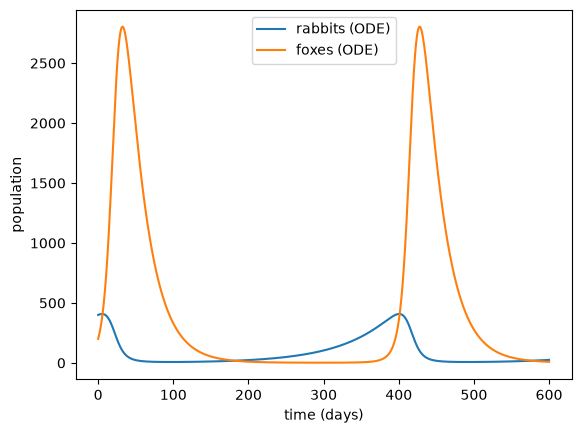

In [15]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:

**Variables:**

$r_1 = k_1$ $R$ $(Rabbit$ $Birth)$

$r_2 = k_2$ $RF$ $(Rabbit$ $Death)$

$r_3 = k_3$ $RF$ $(Fox$ $Birth)$

$r_4 = k_4$ $F$ $(Fox$ $Death)$

$Q_k = r_1 + r_2 + r_3 + r_4$ $(Total$ $Rate)$

$u$ is a random number used to find the event $i$ that satisfies $R_{k,i-1}$ $<$ $uQ_k$ $\le R_{ki}$

$u'$ is a random number used to update time. $\Delta t$ $=$ $Q_{k}^{-1}$ $ln(1/u')$

**Hand Calculation**

$R = 400$

$F = 200$

$u = 0.5$

$u' = 0.3$

$k_1 = 0.015$ $day ^{-1}$

$k_2 = 0.00004$ $day ^{-1}$ $foxes ^{-1}$

$k_3 = 0.0004$ $day ^{-1}$ $rabbits ^{-1}$

$k_4 = 0.04$ $day ^{-1}$

$r_1 (Rabbit$ $Birth)$ $= 0.015$ $\times$ $400 = 6$ $days ^{-1}$

$r_2 (Rabbit$ $Death)$ $= 0.00004$ $\times$ $400$ $\times$ $200 = 3.2$ $days ^{-1}$

$r_3 (Fox$ $Birth)$ $= 0.0004$ $\times$ $400$ $\times$ $200 = 32$ $days ^{-1}$

$r_4 (Fox Death) = 0.04$ $\times$ $200 = 8$ $days ^{-1}$

$Q = 6 + 3.2 + 32 + 8 = 49.2$ $days ^{-1}$

$Event$ $1$ $Interval = [0, 6)$

$Event$ $2$ $Interval = [6, 9.2)$

$Event$ $3$ $Interval = [9.2, 41.2)$

$Event$ $4$ $Interval = [41.2, 49.2)$

$uQ = 0.5$ $\times$ $49.2 = 24.6$

Event 3 happens as 14.76 falls between 9.2 and 41.2

$\Delta t$ $=$ $Q_{k}^{-1}$ $ln(1/u')$

$\Delta t$ $=$ $(1/49.2)$ $\times$ $ln(1/0.3)$

$\Delta t$ $=$ $0.024$ $days$ $= 35.24$ $minutes$*

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

Time taken for KMC simulation = 0.0677 seconds
Number of events = 23328


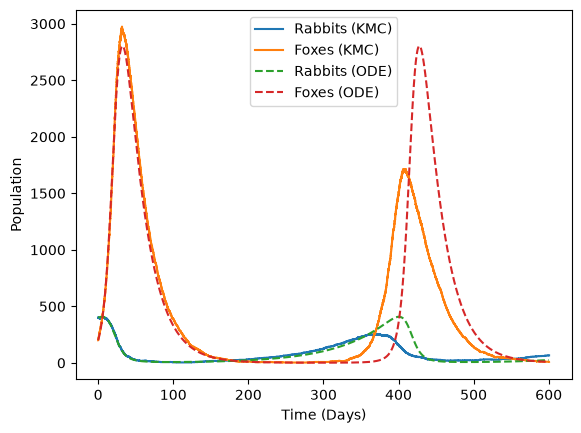

In [16]:
def kmc(R0, F0, t_end, rng):
    t = 0
    R = R0
    F = F0
    t_1 = [t]
    R_1 = [R]
    F_1 = [F]

    while t < t_end:
        r1 = k1 * R
        r2 = k2 * R * F
        r3 = k3 * R * F
        r4 = k4 * F

        Q = r1 + r2 + r3 + r4
        if Q == 0:
            break
        u = rng.random()
        x = u * Q
        if x < r1:
            R = R + 1
        elif x < r1 + r2:
            R = R - 1
        elif x < r1 + r2 + r3:
            F = F + 1
        else:
            F = F - 1

        u_prime = rng.random()
        dt = -np.log(u_prime) / Q
        t = t + dt

        if R < 0 or F < 0:
            raise ValueError(f"Negative Population: R = {R}, F = {F}")

        t_1.append(t)
        R_1.append(R)
        F_1.append(F)

    return np.array(t_1), np.array(R_1), np.array(F_1)

rng = np.random.default_rng(42)

t_i = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
t_f = time.perf_counter()

time_taken = t_f - t_i
print(f"Time taken for KMC simulation = {time_taken:.4f} seconds")
print(f"Number of events = {len(times) - 1}")

plt.step(times, rabbits, where='post', label="Rabbits (KMC)")
plt.step(times, foxes, where='post', label="Foxes (KMC)")
plt.plot(t_ode, R_ode, "--", label="Rabbits (ODE)")
plt.plot(t_ode, F_ode, "--", label="Foxes (ODE)")
plt.xlabel("Time (Days)")
plt.ylabel("Population")
plt.legend()
plt.show()


*Answer: For seed 42, the simulation took 23,328 events and finished in about 0.1027 seconds. When comparing KMC to the ODE, the biggest difference is that KMC moves in discrete integer steps of plus or minus one instead of smooth curves, so the populations never have fractional animals. Because each event happens randomly, the timing and height of the peaks drift away from the ODE curve. In this run, the first fox peak was slightly higher and the second peak happened earlier and was much smaller. Testing other seeds also shows that foxes can easily die out completely when their numbers drop very low in the trough. In the ODE, foxes drop to around 1.6 and always bounce back, but in KMC, once the fox count hits zero, no more foxes can ever be born, leaving the rabbits to grow without any predators.*

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

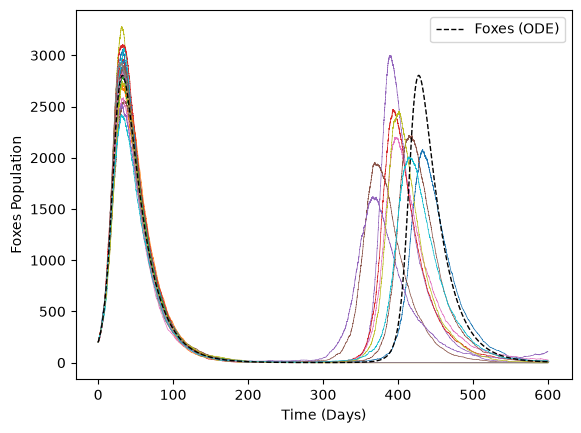

In [17]:
rng = np.random.default_rng(33)

for i in range(20):
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    plt.step(times, foxes, where="post", lw=0.5)
    
plt.plot(t_ode, F_ode, "k--", lw=1, label="Foxes (ODE)")
plt.xlabel("Time (Days)")
plt.ylabel("Foxes Population")
plt.legend()
plt.show()

*Answer:

a) All 20 trajectories closely follow the ODE during the first cycle because populations are large, keeping fluctuations to a small amount. They spread apart significantly during the deep trough days 150–300 when populations drop close to single digits, causing large stochastic variations in the timing and amplitude of the second peak.

b) If the foxes reach 0 (F = 0), then the possibility of both the events fox birth and fox death happening will be 0. The rabbits will then have no threats and they grow exponentially. If the rabbits reach 0 (R = 0), then the events rabbit birth, rabbit death and fox birth will become 0. The remaining foxes will have no more food and can only die through the event fox death until both species reach 0.

c) Foxes die out in the trough around days 180 - 300. In this region, rabbits are nearly depleted, so the fox birth rate drops close to zero while fox mortality continues. Because the population drops to single digits (the ODE falls to around 1.6), random deaths can easily eliminate the final remaining individuals before rabbits recover.*

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

Fraction with second peak: 0.35
Peak Time: mean = 401.6, median = 399.6, iqr = [382.92707698 417.47171773]
Peak Height: mean = 2332.6, median = 2283.0, iqr = [1898.  2682.5]


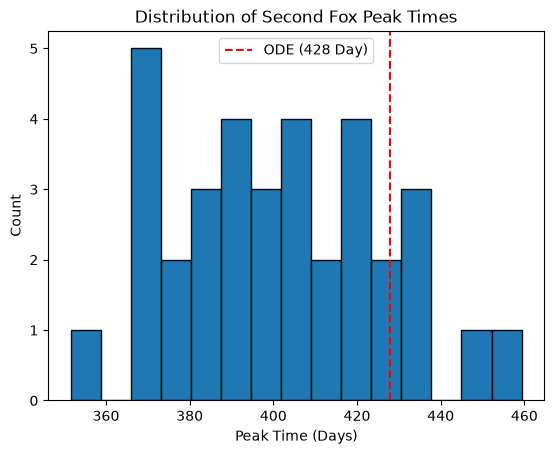

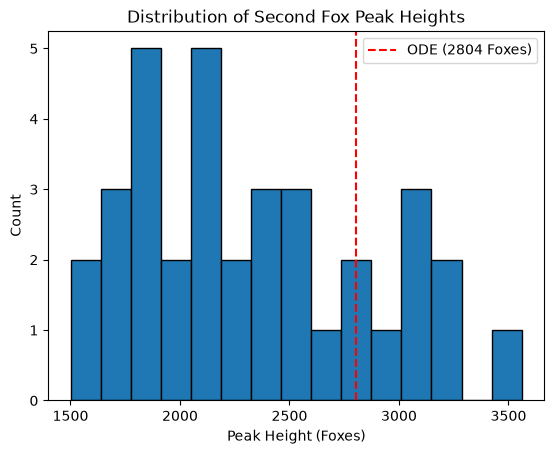

In [18]:
def second_peak(times, foxes):
    x = (205 < times ) & (times < 595)

    t_1 = times[x]
    f_1 = foxes[x]

    if len(f_1) == 0:
        return None

    y = np.argmax(f_1)
    fox_max = f_1[y]

    if fox_max > 100:
        return t_1[y], fox_max
    else:
        return None

rng = np.random.default_rng(30)
peak_time = []
peak_height = []

for i in range(100):
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    result = second_peak(times, foxes)
    if result is not None:
        t_2, f_2 = result
        peak_time.append(t_2)
        peak_height.append(f_2)

peak_time = np.array(peak_time)
peak_height = np.array(peak_height)

print(f"Fraction with second peak: {len(peak_time) / 100:.2f}")
print(f"Peak Time: mean = {np.mean(peak_time):.1f}, median = {np.median(peak_time):.1f}, iqr = {np.percentile(peak_time, [25, 75])}")
print(f"Peak Height: mean = {np.mean(peak_height):.1f}, median = {np.median(peak_height):.1f}, iqr = {np.percentile(peak_height, [25, 75])}")

plt.figure()
plt.hist(peak_time, bins=15, edgecolor = "black")
plt.axvline(428, color="red", linestyle="--", label="ODE (428 Day)")
plt.xlabel("Peak Time (Days)")
plt.ylabel("Count")
plt.title("Distribution of Second Fox Peak Times")
plt.legend()
plt.show()

plt.figure()
plt.hist(peak_height, bins=15, edgecolor="black")
plt.axvline(2804, color="red", linestyle="--", label="ODE (2804 Foxes)")
plt.xlabel("Peak Height (Foxes)")
plt.ylabel("Count")
plt.title("Distribution of Second Fox Peak Heights")
plt.legend()
plt.show()

*Answer: In the ODE, the second peak occurs at day 428 with a height of 2804 foxes. In KMC, the surviving peaks arrive a bit earlier, median (~400 days) and are lower on average (median ~2283). The surviving trajectories depend on survival through the trough. If the fox population drops to a few individuals rather than the fractional ~1.6 foxes of the ODE, rabbits can grow faster without any predatory threat. A rapid rabbit explosion leads to earlier fox recovery, while variations in predation timing often cut off the peak before reaching the deterministic height.

The peak definition just takes whatever the highest point is between days 205 and 595 as long as it gets over 100. I think this mostly messes up because 100 foxes isn't really that many, so sometimes a run that is almost dead just gets a tiny bump over 100 and it counts that as the second peak even though it wasn't a real comeback. Also, if the curve is still going up at the very end around day 590, it might just pick that spot because it ran out of time instead of waiting for the real peak.*

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

*Answer:*

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

*Answer:*

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.